# ЛР 1. Начало работы с ML-проектом: формализация задачи и первичный анализ данных
<!-- В VSCode есть специальное расширение для генерации интерактивного оглавления -->
<!-- Желательно в оглавлении сохранить нумерацию пунктов -->
<!-- Правилом хорошего тона является создание интерактивных заголовков пунктов и подпунктов, которые ведут на оглавление -->

**Table of contents**<a id='toc0_'></a>

## Описание задачи
**1. Предметная область и боли заказчика:**
Заказчиком выступает король Эйгон I Таргариен, который строит Красный замок. Крепость должна выдерживать осады и быть максимально надежной. Мейстеры провели испытания строительной смеси. 

*Боль заказчика (Эйгона):* Он не хочет слепо доверять мастерам и желает знать наверняка: от чего сильнее зависит прочность стены — от самой смеси или от времени её выдержки? Строительство нельзя тормозить просто так, поэтому нужно обосновать, имеет ли смысл долго ждать усадки.

*Суть гипотезы Эйгона:* Влияет ли время на итоговую прочность стен так же сильно (или даже сильнее), чем состав смеси?

**2. Постановка ML-задачи:**
Перед нами стоит задача **регрессии** (Regression), так как целевая переменная (прочность на сжатие) является непрерывной вещественной величиной. Дополнительной (и главной) задачей является **анализ важности признаков (гипотеза Эйгона)**, чтобы ответить на вопрос короля о влиянии состава смеси против влияния времени.

**3. Объект задачи:**
Объектом исследования является отдельный образец строительной смеси, для которого известен состав, время выдержки и итоговая прочность.

**4. Образ выходного результата модели:**
На выходе модель должна предсказывать точное число — прочность материала на сжатие. Также результатом работы станет аналитический вывод о том, какой фактор вносит наибольший вклад в прочность.

`ячейки для описания исходных данных`
<!-- 
    В этой и последующих ячейках предлагается описать исходные данные, а также сопутствующую информацию:
    1. таблицу с семантикой данных, а также типами данных столбцов (ожидаемый тип, а не фактический, которые мы получаем при чтении данных) в формате MD (кодом не надо выводить таблички)
    2. формулы прикладной области (с указанием, какие формулы можно использовать, а какие -- нет)
-->

## Описание исходных данных и их семантика (Data Understanding)

Набор данных представляет собой результаты испытаний образцов строительной смеси. Все признаки являются числовыми (вещественными).

| Название признака (столбец) | Семантика (описание) | Ожидаемый тип данных | Роль |
| :--- | :--- | :--- | :--- |
| **Cement** | Количество цемента в смеси (кг/м³) | `float` | Входной |
| **Blast Furnace Slag** | Доменной шлак (кг/м³) | `float` | Входной |
| **Fly Ash** | Зола-унос (кг/м³) | `float` | Входной |
| **Water** | Количество воды (кг/м³) | `float` | Входной |
| **Superplasticizer** | Суперпластификатор (кг/м³) | `float` | Входной |
| **Coarse Aggregate** | Крупный заполнитель / щебень (кг/м³) | `float` | Входной |
| **Fine Aggregate** | Мелкий заполнитель / песок (кг/м³) | `float` | Входной |
| **Age** | Время выдержки материала (в днях) | `float` | Входной |
| **Concrete compressive strength** | Прочность на сжатие (МПа) | `float` | **Целевой** |

`Доменный шлак` — это побочный продукт, который образуется при выплавке чугуна в доменной печи. Проще говоря, это «отход» металлургического производства, который раньше просто выбрасывали, а сейчас активно используют в строительстве. 

`Зола-унос (или летучая зола)` — это тонкодисперсный порошок, который образуется при сжигании твёрдого топлива, чаще всего угля, на тепловых электростанциях.

`Суперпластификатор` — это такая «волшебная» добавка в бетонную смесь, которая делает её гораздо более пластичной и текучей, чем обычно. При этом не нужно добавлять лишнюю воду, чтобы смесь было легко заливать.

## Формулы прикладной области

### Водовяжущее отношение 
— это отношение массы воды к массе вяжущего вещества после затворения смеси. Этот параметр используется в строительстве, в частности при работе с бетонными смесями, где часть цемента может заменяться минеральными добавками (например, золой-уноса, доменным гранулированным шлаком, микрокремнезёмом). 

Новый признак (Binder): $Binder = Cement + Slag + Fly Ash$

Новый признак (W/B): $W/B = \frac{Water}{Binder}$

---
### Формула Боломея-Скрамтаева
Для бетонов средней и высокой прочности закон Абрамса часто заменяют линейной формулой Боломея-Скрамтаева, которая использует обратное отношение (цемент к воде):$$R = A \cdot R_c \cdot \left( \frac{C}{W} - 0.5 \right)$$Где $C/W$ — цементно-водное отношение.Новый признак: $\frac{Cement}{Water}$ или $\frac{Binder}{Water}$. 

Поскольку $A$ и $R_c$ для конкретной выборки являются константами (или скрытыми параметрами), задача алгоритма — самостоятельно подобрать такие веса, которые заменят эти неизвестные множители.

`справка` $R_c$ (Активность или марка цемента): Это физико-механическая характеристика самого цемента (например, цемент марки М400 или М500). $A$ (Коэффициент качества): Это эмпирический коэффициент, зависящий от качества заполнителей (щебня и песка). 

---
### Логарифмический закон роста прочности во времени 
— это эмпирическая зависимость, которая приближённо описывает процесс увеличения прочности материалов (например, бетона на основе цементного вяжущего) с течением времени. 

`Суть закона`

Согласно этому закону, прочность материала сначала растёт интенсивно, а затем темп замедляется. Математически это выражается тем, что зависимость прочности от времени в обычном масштабе является логарифмической функцией, а в логарифмическом масштабе времени — линейной.

`Формула расчёта`

$$R_n = R_{28} \cdot \frac{\log(n)}{\log(28)}$$

где:
Rₙ — прочность бетона в возрасте n суток;
R₂₈ — прочность в возрасте 28 суток;

Новый признак: $Log\_Age = \log(Age)$

---

В строительстве (и в записях мейстеров) базовым правилом оценки прочности является **Закон Абрамса (Abrams' law)**. Он гласит, что прочность смеси обратно пропорциональна водоцементному отношению (отношению массы воды к массе цемента):

$$ S = \frac{A}{B^{W/C}} $$

Где:
* $S$ — прочность материала
* $W/C$ — отношение массы воды к массе цемента (признак Water разделить на признак Cement)
* $A$ и $B$ — константы, зависящие от внешних условий.

### Вывод: использование формул в ML-задаче

Опираясь на описанные выше физические законы прочности, мы должны четко разделить их применимость в рамках нашего ML-проекта:

**Что использовать НЕЛЬЗЯ:**
Нельзя применять формулу Боломея-Скрамтаева или закон Абрамса напрямую для аналитического (ручного) расчета целевой переменной (прочности на сжатие), подменяя тем самым модель машинного обучения. Эти эмпирические формулы идеализированы, они требуют знания скрытых коэффициентов (качество заполнителей $A$, истинная марка цемента $R_c$) и не умеют корректно учитывать влияние современных химических добавок (например, суперпластификатора). Алгоритм должен сам найти веса и зависимости.

**Что использовать МОЖНО:**
Можно (и нужно) использовать математическую **структуру** этих формул на этапе генерации новых признаков (Feature Engineering). Мы имеем полное право создать новые столбцы в нашем датасете, опираясь на физику процесса:
1. Водовяжущее отношение ($W/B$) или обратное ему ($Binder/Water$).
2. Логарифм возраста ($Log\_Age$).

`ячейки для создания и фиксации виртуального окружения`
<!-- 
    В этой и последующих ячейках предлагается зафиксировать информацию о виртуальном окружении, а именно:
    1. версию питона
    2. версию и список используемых библиотек
    3. основные и часто встречающиеся импорты (pandas, numpy, typing, warnings и т.д.)
    4. случайный сид (seed / random_state)
-->

In [1]:
!python --version # Версия Python

Python 3.13.2


In [2]:
!pip list # Список и версии библиотек

Package                   Version
------------------------- ----------
anyio                     4.15.1
argon2-cffi               25.1.0
argon2-cffi-bindings      26.1.0
arrow                     1.4.0
asttokens                 3.0.2
async-lru                 2.4.0
attrs                     26.1.0
babel                     2.18.0
beautifulsoup4            4.15.0
bleach                    6.4.0
certifi                   2026.10.23
cffi                      2.1.1
charset-normalizer        3.5.2
cloudpickle               3.1.2
colorama                  0.4.6
comm                      0.2.3
contourpy                 1.4.0
cycler                    0.12.1
debugpy                   1.8.22
defusedxml                0.7.1
executing                 2.3.0
fastjsonschema            2.22.2
fonttools                 4.68.0
fqdn                      1.6.0
h11                       0.16.0
httpcore                  1.0.9
httpx                     0.28.1
idna                      3.20
ipykernel        

In [3]:
# Базовые библиотеки для работы с таблицами и массивами
import pandas as pd
import numpy as np

# Настройка предупреждений
import warnings
warnings.filterwarnings('ignore')

# Инструмент для разделения выборки
from sklearn.model_selection import train_test_split

# Фиксация случайного сида для воспроизводимости
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1. Предварительная обработка данных

## 1.1. Чтение и загрузка данных 

In [4]:
# Загрузка данных
df = pd.read_csv('../../data/game_of_thrones.csv', sep=';')

In [5]:
df.head(20)

,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
0,540.0,0.0,0.0,NaN,2.5,1040.0,676.0,28.0,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,NaN,90.0,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365.0,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28.0,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28.0,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28.0,39.29


## 1.2. Первичный анализ данных

Первоначально необходимо проанализировать типы данных колонок датафрейма и проверить наличие пропущенных значений. Воспользуемся методом датафрейма `.info()`, который выводит сводную информацию об объекте. Дополнительно применим метод `.describe()` для оценки распределения (среднее, минимум, максимум, квартили) числовых признаков. 
Это поможет нам понять, готовы ли данные к делению на обучающую и тестовую выборки.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement kg/m^3                  968 non-null    float64
 1   Blast Furnace Slag kg/m^3      958 non-null    float64
 2   Fly Ash kg/m^3                 948 non-null    float64
 3   Water kg/m^3                   948 non-null    float64
 4   Superplasticizer kg/m^3        937 non-null    float64
 5   Coarse Aggregate kg/m^3        927 non-null    float64
 6   Fine Aggregate kg/m^3          906 non-null    float64
 7   Age day                        978 non-null    float64
 8   Concrete compressive strength  1030 non-null   float64
dtypes: float64(9)
memory usage: 72.6 KB


1. **Типы данных:** Все 9 признаков корректно спарсились как вещественные числа (`float64`). Приведение типов не требуется, данные соответствуют заявленной семантике.

2. **Целевая переменная:** Признак `Concrete compressive strength` не имеет пропусков (1030 non-null из 1030). Это значит, что удаление строк из-за отсутствия целевой метки не потребуется.

3. **Наличие пропущенных значений:** Во всех входных признаках (от `Cement` до `Age`) присутствуют пропущенные значения (NaN), так как количество non-null значений везде меньше 1030. Следовательно, на этапе предварительной обработки будет необходимо применить стратегии заполнения пропусков. 

In [7]:
df.describe()

,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
count,968.000000,958.000000,948.00000,948.000000,937.000000,927.000000,906.000000,978.000000,1030.000000
mean,280.409814,73.453758,53.48692,181.708228,6.202455,972.645847,773.029470,45.721881,35.817961
std,103.923736,86.313283,64.16564,21.642256,5.968103,78.112692,79.723362,63.983704,16.705742
min,102.000000,0.000000,0.00000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,190.700000,0.000000,0.00000,164.900000,0.000000,932.000000,733.250000,7.000000,23.710000
50%,272.700000,20.000000,0.00000,185.000000,6.400000,968.000000,778.500000,28.000000,34.445000
75%,350.000000,144.150000,118.30000,192.900000,10.200000,1029.400000,823.550000,56.000000,46.135000
max,540.000000,359.400000,200.10000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


1. **Все значения неотрицательны**, что полностью соответствует физическому смыслу признаков (масса и время).

2. **Разность масштабов:** Разброс значений колоссален (от единиц у `Superplasticizer` до тысяч у `Coarse Aggregate`). Это означает обязательную необходимость скалирования признаков на следующих этапах.

3. **Естественные нули:** Минимум (а иногда и медиана) у шлака, золы и пластификатора равен 0. Это нормально — данные добавки применяются не в каждой смеси.

4. **Специфика `Age`:** Медиана составляет 28 дней (стандарт тестирования), но есть сильный правый хвост (максимум 365). Такой разброс подтверждает нашу гипотезу о необходимости логарифмирования возраста для обучения. Разница между 1 и 28 днем огромная (там достигается 90% прочности), а дальше уже почти нулевая. Но машина этого не понимает и подумает, что за такое время прочность должна была вырасти в разы. Как спасает логарифм? В математике логарифмирование — это функция, которая "сжимает" большие числа и "растягивает" маленькие. Если мы вместо самих дней возьмем их логарифм, то машина увидит, что промежуток от 1 до 28 дней имеет большой вес, а огромный скачок от 180 до 365 дней превратится в маленький шажок.

In [8]:
df.nunique()

Cement kg/m^3                    273
Blast Furnace Slag kg/m^3        180
Fly Ash kg/m^3                   146
Water kg/m^3                     188
Superplasticizer kg/m^3          110
Coarse Aggregate kg/m^3          274
Fine Aggregate kg/m^3            280
Age day                           14
Concrete compressive strength    845
dtype: int64

1. В целевой переменной (`Concrete compressive strength`) целых 845 разных значений на 1030 строк. То есть мы предсказываем конкретное дробное число, а не просто категории "крепкий/хрупкий". Значит, это точно задача регрессии.

2. Во всех признаках состава смеси уникальных значений больше сотни. Категориальных колонок (текстовых или где всего 2-3 варианта ответа) у нас вообще нет. Получается шаг с кодированием категорий можно будет просто пропустить.

3. `Age` имеет всего 14 уникальных значений. Это значит, что бетон тестировали не каждый день подряд, а только в строго определенные контрольные дни (например, на 7-й, 14-й, 28-й день и т.д.), как это обычно и делают в лабораториях.

## 1.3. Разделение выборки на обучающую и тестовую выборки

In [9]:
y = df['Concrete compressive strength']
X = df.drop(['Concrete compressive strength'], axis = 1)

In [10]:
y

0       79.99
1       61.89
2       40.27
3       41.05
4       44.30
        ...  
1025    44.28
1026    31.18
1027    23.70
1028    32.77
1029    32.40
Name: Concrete compressive strength, Length: 1030, dtype: float64

In [11]:
X

,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day
0,540.0,0.0,0.0,NaN,2.5,1040.0,676.0,28.0
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0
...,...,...,...,...,...,...,...,...
1025,276.4,NaN,90.3,179.6,8.9,NaN,768.3,28.0
1026,322.2,0.0,115.6,NaN,NaN,817.9,813.4,28.0
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28.0
1028,159.1,186.7,NaN,175.6,11.3,989.6,788.9,28.0


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=True, random_state=42, test_size=0.2)

In [13]:
print(f"Размер X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Размер X_test:  {X_test.shape}, y_test:  {y_test.shape}")

Размер X_train: (824, 8), y_train: (824,)
Размер X_test:  (206, 8), y_test:  (206,)


## ЛР 2. Устранение проблем в данных: заполнение пропусков и кодирование категориальных признаков

## 2.1 Обработка вещественных признаков (заполнение пропусков)

Пропуски в данных у нас имеются, посмотрим их количество по колонкам:

In [14]:
df.isnull().sum()

Cement kg/m^3                     62
Blast Furnace Slag kg/m^3         72
Fly Ash kg/m^3                    82
Water kg/m^3                      82
Superplasticizer kg/m^3           93
Coarse Aggregate kg/m^3          103
Fine Aggregate kg/m^3            124
Age day                           52
Concrete compressive strength      0
dtype: int64

В целевых значениях пропусков не обнаружено. Доля пропусков в колонках не превышает 20%, соответственно будем не удалять, а пытаться заполнять. Для этого воспользуемся машинным и статистическим подходом и сравним результаты.

### Статистические подходы

Долго думать не будем и просто бахнем медиану, в контексте нашей бизнес задачи звучит вполне разумно

In [15]:
xtrain_stat = X_train.copy()
xtest_stat = X_test.copy()

In [16]:
for col in xtrain_stat.select_dtypes(include='number').columns:
    median = xtrain_stat[col].median()
    xtrain_stat[col] = xtrain_stat[col].fillna(median)
    xtest_stat[col] = xtest_stat[col].fillna(median)

Теперь надо проверить, чего там вообще назаполнялось... Используем для этого KL-дивергенцию и построим диаграммы

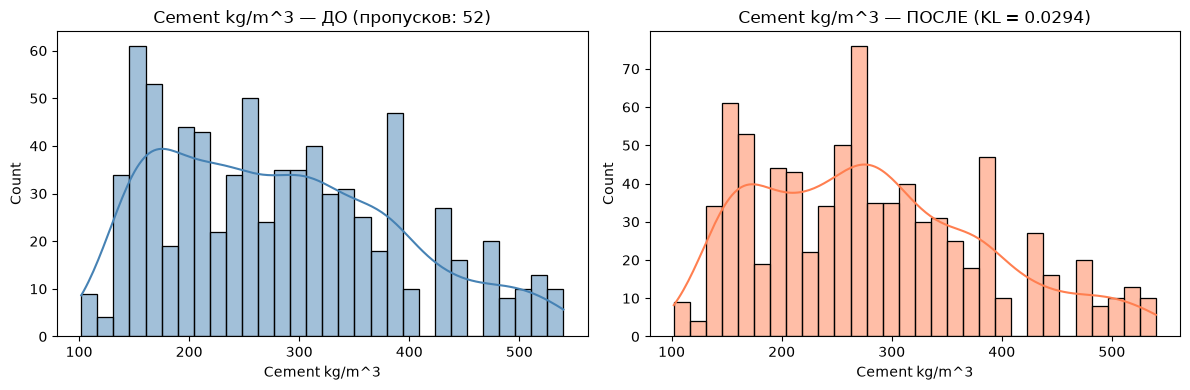

Cement kg/m^3: KL = 0.0294


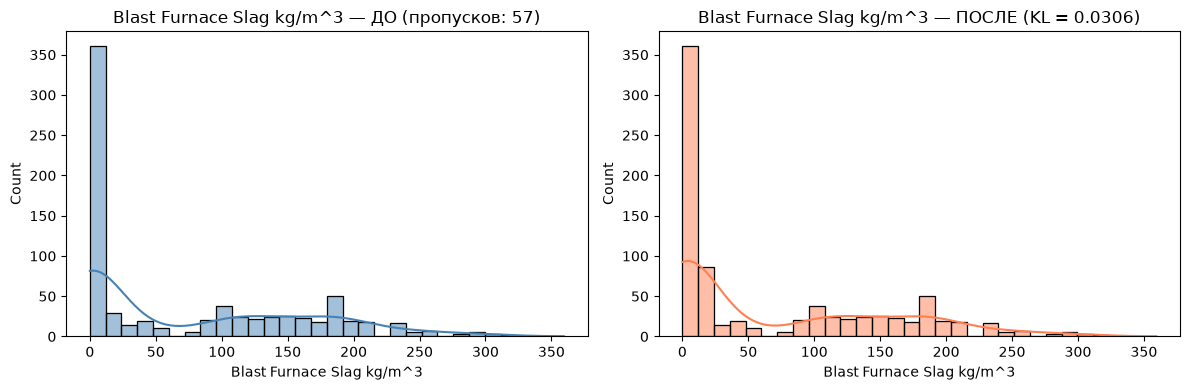

Blast Furnace Slag kg/m^3: KL = 0.0306


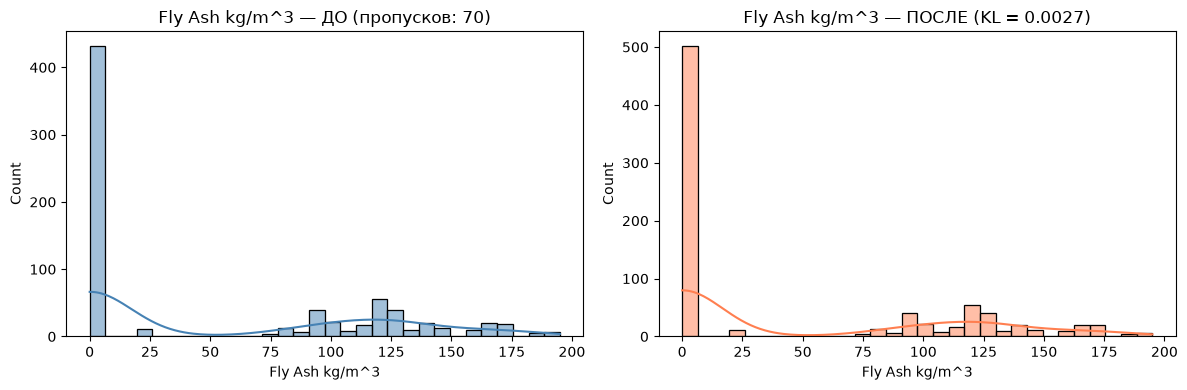

Fly Ash kg/m^3: KL = 0.0027


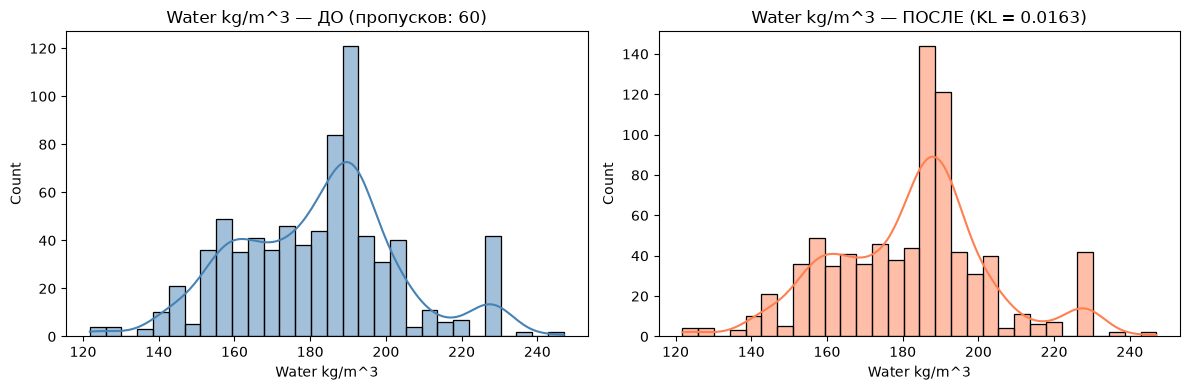

Water kg/m^3: KL = 0.0163


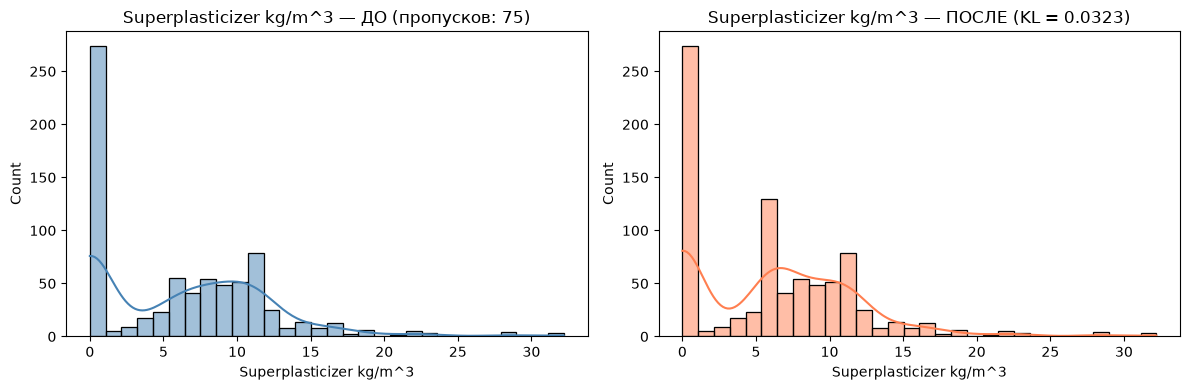

Superplasticizer kg/m^3: KL = 0.0323


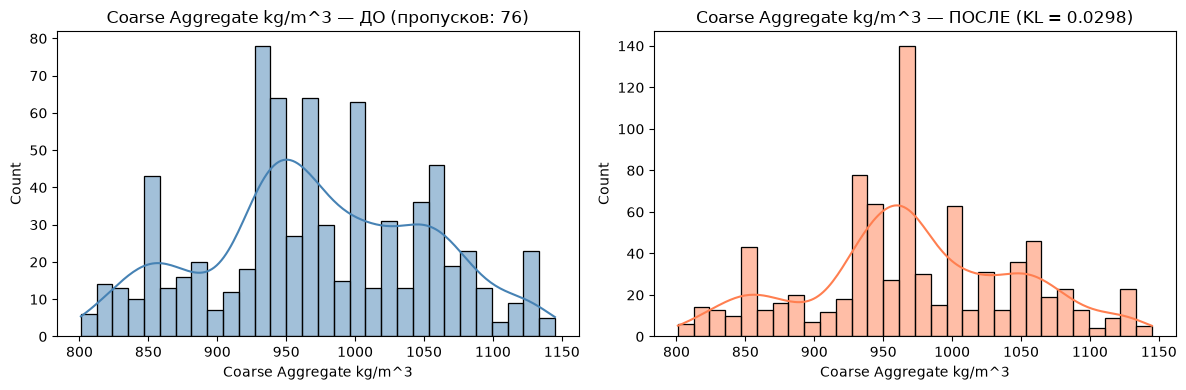

Coarse Aggregate kg/m^3: KL = 0.0298


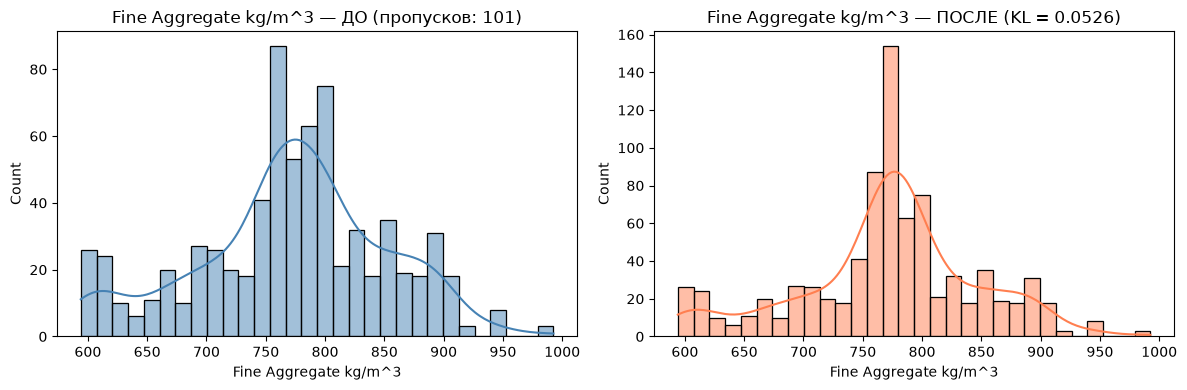

Fine Aggregate kg/m^3: KL = 0.0526


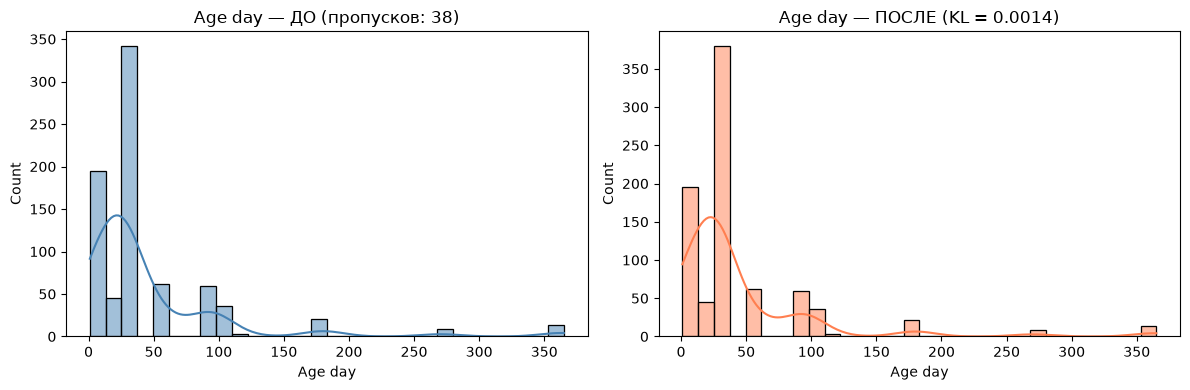

Age day: KL = 0.0014


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

for col in xtrain_stat.select_dtypes(include='number').columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    before = X_train[col].dropna()
    after  = xtrain_stat[col]
    
    
    min_val = min(before.min(), after.min())
    max_val = max(before.max(), after.max())
    bin_edges = np.linspace(min_val, max_val, 31)  
    
    # строим частотные гистограммы и считаем вероятности
    hist_before, _ = np.histogram(before, bins=bin_edges)
    hist_after,  _ = np.histogram(after,  bins=bin_edges)
    
    p = hist_before / hist_before.sum()
    q = hist_after  / hist_after.sum()
    
    
    mask = (p > 0) & (q > 0)
    p_masked = p[mask]
    q_masked = q[mask]
    
    
    kl = np.sum(p_masked * np.log(p_masked / q_masked))
    
    
    sns.histplot(before, bins=30, kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{col} — ДО (пропусков: {X_train[col].isnull().sum()})')
    
    sns.histplot(after, bins=30, kde=True, ax=axes[1], color='coral')
    axes[1].set_title(f'{col} — ПОСЛЕ (KL = {kl:.4f})')
    
    plt.tight_layout()
    plt.show()
    
    print(f'{col}: KL = {kl:.4f}')

Исходя из полученных распределений до и после заполнения, видим, что показатель KL у каждого из признаков <= 0.05, это говорит о том, что стратегия заполнения пропусков почти не исказила распределения, импутация статистически корректна
Для четсности жксперимента попробуем заполнить средним значением:

In [18]:
xtrain_stat = X_train.copy()
xtest_stat = X_test.copy()

In [19]:
for col in xtrain_stat.select_dtypes(include='number').columns:
    median = xtrain_stat[col].mean()
    xtrain_stat[col] = xtrain_stat[col].fillna(median)
    xtest_stat[col] = xtest_stat[col].fillna(median)

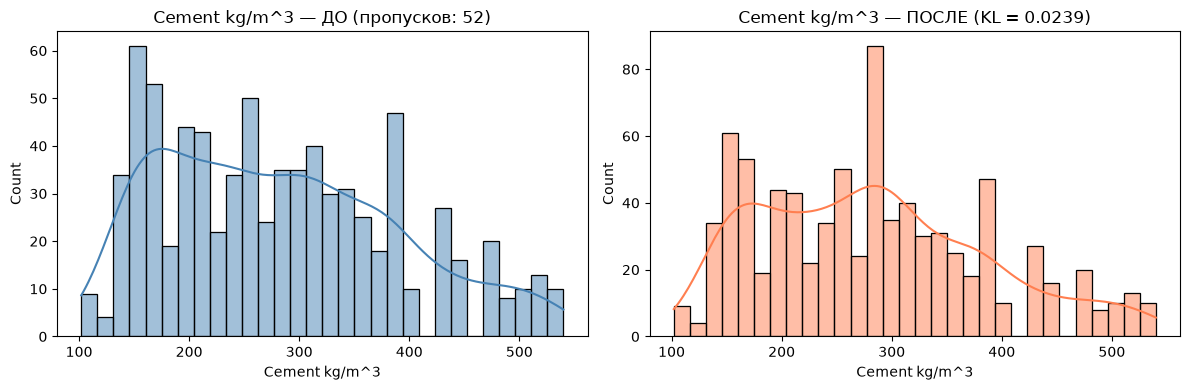

Cement kg/m^3: KL = 0.0239


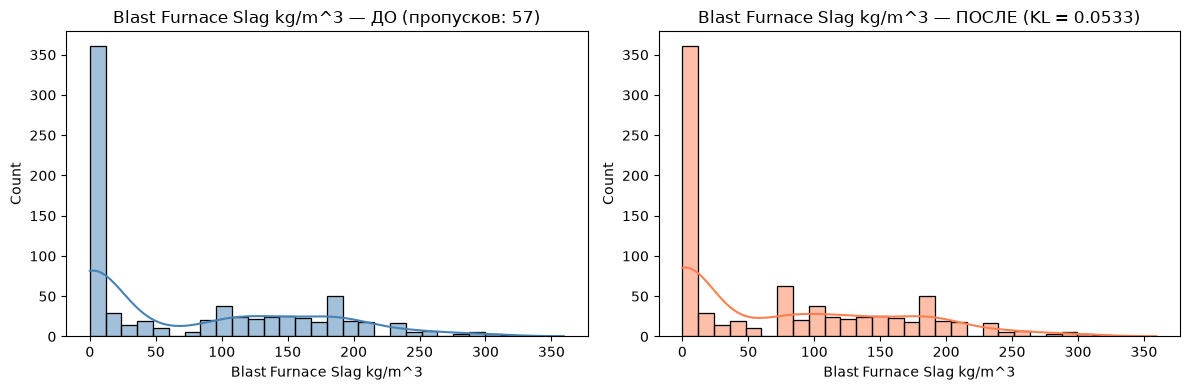

Blast Furnace Slag kg/m^3: KL = 0.0533


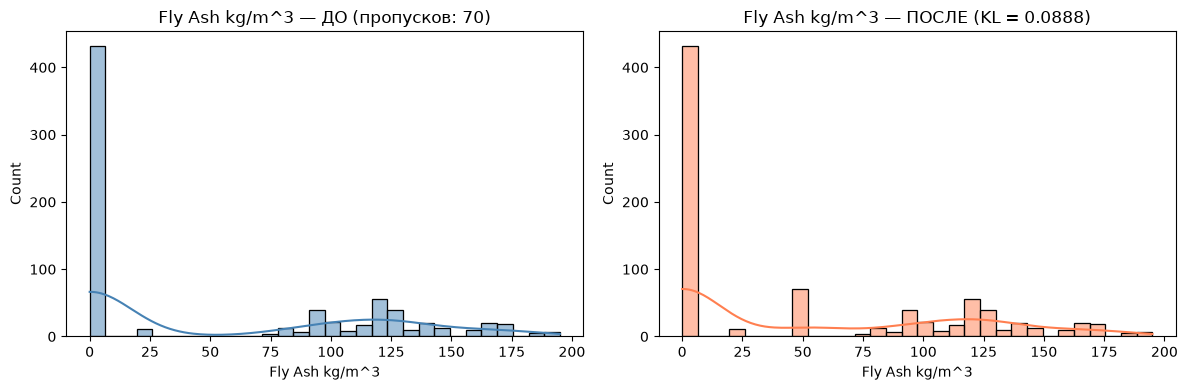

Fly Ash kg/m^3: KL = 0.0888


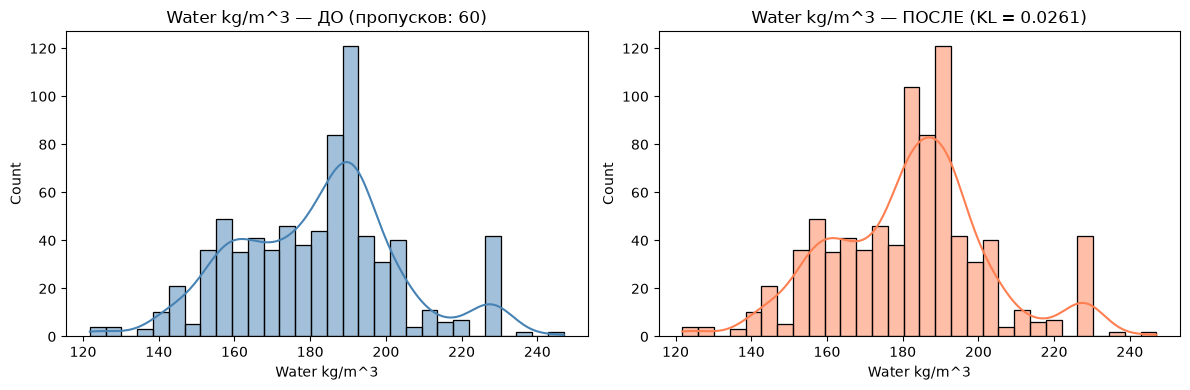

Water kg/m^3: KL = 0.0261


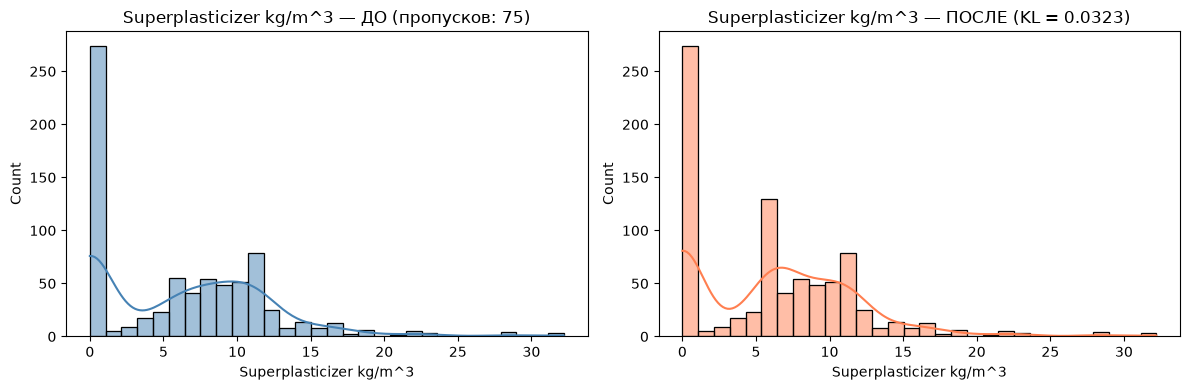

Superplasticizer kg/m^3: KL = 0.0323


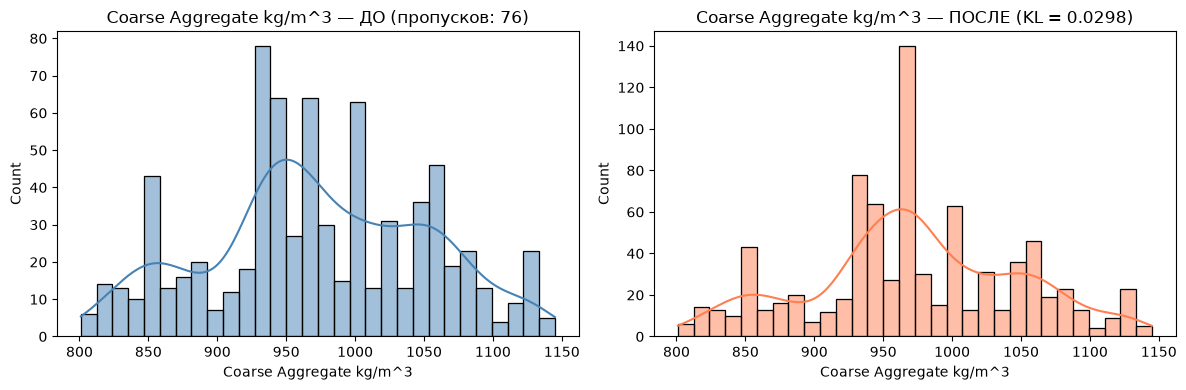

Coarse Aggregate kg/m^3: KL = 0.0298


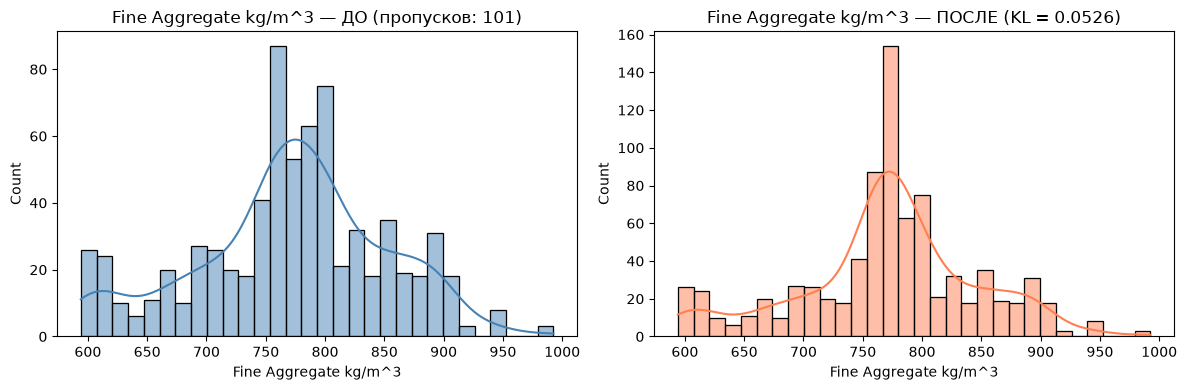

Fine Aggregate kg/m^3: KL = 0.0526


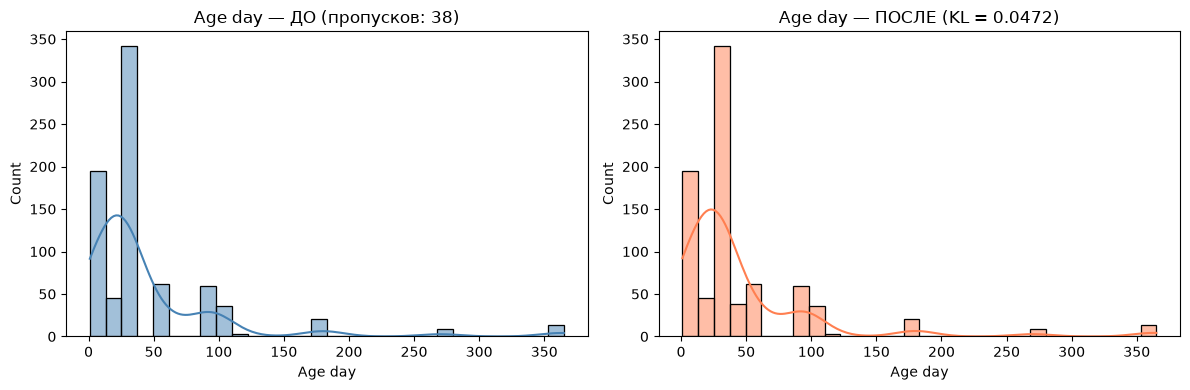

Age day: KL = 0.0472


In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

for col in xtrain_stat.select_dtypes(include='number').columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    before = X_train[col].dropna()
    after  = xtrain_stat[col]
    
    
    min_val = min(before.min(), after.min())
    max_val = max(before.max(), after.max())
    bin_edges = np.linspace(min_val, max_val, 31)  
    
    # строим частотные гистограммы и считаем вероятности
    hist_before, _ = np.histogram(before, bins=bin_edges)
    hist_after,  _ = np.histogram(after,  bins=bin_edges)
    
    p = hist_before / hist_before.sum()
    q = hist_after  / hist_after.sum()
    
    
    mask = (p > 0) & (q > 0)
    p_masked = p[mask]
    q_masked = q[mask]
    
    
    kl = np.sum(p_masked * np.log(p_masked / q_masked))
    
    
    sns.histplot(before, bins=30, kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{col} — ДО (пропусков: {X_train[col].isnull().sum()})')
    
    sns.histplot(after, bins=30, kde=True, ax=axes[1], color='coral')
    axes[1].set_title(f'{col} — ПОСЛЕ (KL = {kl:.4f})')
    
    plt.tight_layout()
    plt.show()
    
    print(f'{col}: KL = {kl:.4f}')

Средним похуже, но все еще ок, однаком we`ll stick to медиана в этом кейсе


### Машинные подходы

In [21]:
xtrain_mach = X_train.copy()
xtest_mach = X_test.copy()

In [22]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer


imputer_test = IterativeImputer(max_iter=100, random_state=42)
xtest_mach = pd.DataFrame(imputer_test.fit_transform(xtrain_mach), columns=xtrain_mach.columns)

In [23]:
from sklearn.metrics import mean_squared_error
import numpy as np

nrmse = {}
for col in xtrain_stat.select_dtypes(include='number').columns:
    # Маска: True там, где значение БЫЛО (не NaN)
    known_mask = X_train[col].notna()
    
    true_vals   = X_train.loc[known_mask, col]
    filled_vals = xtrain_mach.loc[known_mask, col]
    
    mse  = mean_squared_error(true_vals, filled_vals)
    rmse = np.sqrt(mse)
    nrmse[col] = rmse / X_train[col].std()

print("NRMSE по колонкам:")
for col, val in nrmse.items():
    print(f"{col}: {val:.3f}")

NRMSE по колонкам:
Cement kg/m^3: 0.000
Blast Furnace Slag kg/m^3: 0.000
Fly Ash kg/m^3: 0.000
Water kg/m^3: 0.000
Superplasticizer kg/m^3: 0.000
Coarse Aggregate kg/m^3: 0.000
Fine Aggregate kg/m^3: 0.000
Age day: 0.000


In [24]:
import numpy as np
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor


rf = RandomForestRegressor()

# берем данные, где нет пропусков
numeric_train = X_train.select_dtypes(include='number')
data_true = numeric_train.dropna().copy()




nan_columns = [col for col in numeric_train.columns if numeric_train[col].isnull().any()]

# искусственная генерация пропусков
np.random.seed(42)
mask = np.zeros(data_true.shape, dtype=bool)

for col in nan_columns:
    col_idx = data_true.columns.get_loc(col)
    col_mask = np.random.rand(len(data_true)) < 0.2
    mask[:, col_idx] = col_mask

data_masked = data_true.copy()
data_masked[mask] = np.nan


imputer = IterativeImputer(max_iter=100, random_state=42, estimator=rf)
data_filled = pd.DataFrame(
    imputer.fit_transform(data_masked),
    columns=data_masked.columns,
    index=data_masked.index
)


nrmse = {}
for col in nan_columns:
    col_idx = data_true.columns.get_loc(col)
    col_mask = mask[:, col_idx]
    
    if col_mask.sum() == 0:
        continue
    
    true_vals   = data_true.loc[col_mask, col]
    filled_vals = data_filled.loc[col_mask, col]
    
    mse  = mean_squared_error(true_vals, filled_vals)
    rmse = np.sqrt(mse)
    nrmse[col] = rmse / data_true[col].std()

print("NRMSE по колонкам:")
for col, val in nrmse.items():
    print(f"{col}: {val:.3f}")

NRMSE по колонкам:
Cement kg/m^3: 0.617
Blast Furnace Slag kg/m^3: 0.720
Fly Ash kg/m^3: 0.725
Water kg/m^3: 0.581
Superplasticizer kg/m^3: 0.672
Coarse Aggregate kg/m^3: 0.732
Fine Aggregate kg/m^3: 0.686
Age day: 1.219


Ну это очень плохо... Начальство не оценит, так что заполним медианой и не будем выпендриваться

In [25]:
for col in X_train.select_dtypes(include='number').columns:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

In [26]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 824 entries, 995 to 860
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Cement kg/m^3              824 non-null    float64
 1   Blast Furnace Slag kg/m^3  824 non-null    float64
 2   Fly Ash kg/m^3             824 non-null    float64
 3   Water kg/m^3               824 non-null    float64
 4   Superplasticizer kg/m^3    824 non-null    float64
 5   Coarse Aggregate kg/m^3    824 non-null    float64
 6   Fine Aggregate kg/m^3      824 non-null    float64
 7   Age day                    824 non-null    float64
dtypes: float64(8)
memory usage: 57.9 KB


In [27]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 206 entries, 31 to 602
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Cement kg/m^3              206 non-null    float64
 1   Blast Furnace Slag kg/m^3  206 non-null    float64
 2   Fly Ash kg/m^3             206 non-null    float64
 3   Water kg/m^3               206 non-null    float64
 4   Superplasticizer kg/m^3    206 non-null    float64
 5   Coarse Aggregate kg/m^3    206 non-null    float64
 6   Fine Aggregate kg/m^3      206 non-null    float64
 7   Age day                    206 non-null    float64
dtypes: float64(8)
memory usage: 14.5 KB


## 2.2 Кодирование категориальных признаков

Категориальных признаков у нас нет, ТРОЕКРРРАТНОЕ УРРА!

## ЛР 3. Детекция выбросов и аномалий в данных

## 3.1. Детекция выбросов в данных

Прошлый коллега не удосужился соединить икс воедино, так что работаем за бесплатно

In [28]:
X_clean = pd.concat([X_train, X_test]).sort_index()

In [29]:
X_clean.info()

<class 'pandas.DataFrame'>
Index: 1030 entries, 0 to 1029
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Cement kg/m^3              1030 non-null   float64
 1   Blast Furnace Slag kg/m^3  1030 non-null   float64
 2   Fly Ash kg/m^3             1030 non-null   float64
 3   Water kg/m^3               1030 non-null   float64
 4   Superplasticizer kg/m^3    1030 non-null   float64
 5   Coarse Aggregate kg/m^3    1030 non-null   float64
 6   Fine Aggregate kg/m^3      1030 non-null   float64
 7   Age day                    1030 non-null   float64
dtypes: float64(8)
memory usage: 72.4 KB


### Визуализация "ящика с усами" и гистограммы с границами для выбросов (IQR и Z-score)

Сразу построим графики вместе, чтобы нагляднее оценить данные. Каждая строчка (два графика) - один признак, правый график - гистограмма с красными границами для метода IQR (квартильный анализ) и с зелеными границами для метода Z-score (метод стандартизированной оценки)

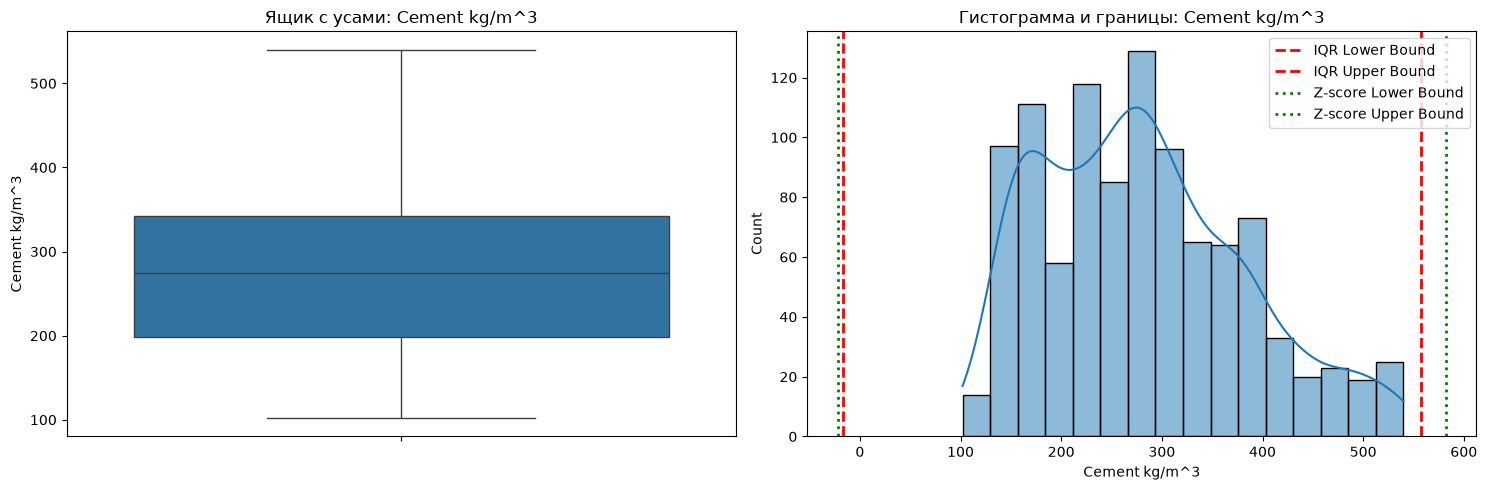

По признаку 'Cement kg/m^3' общих выбросов (IQR + Z-score) не найдено



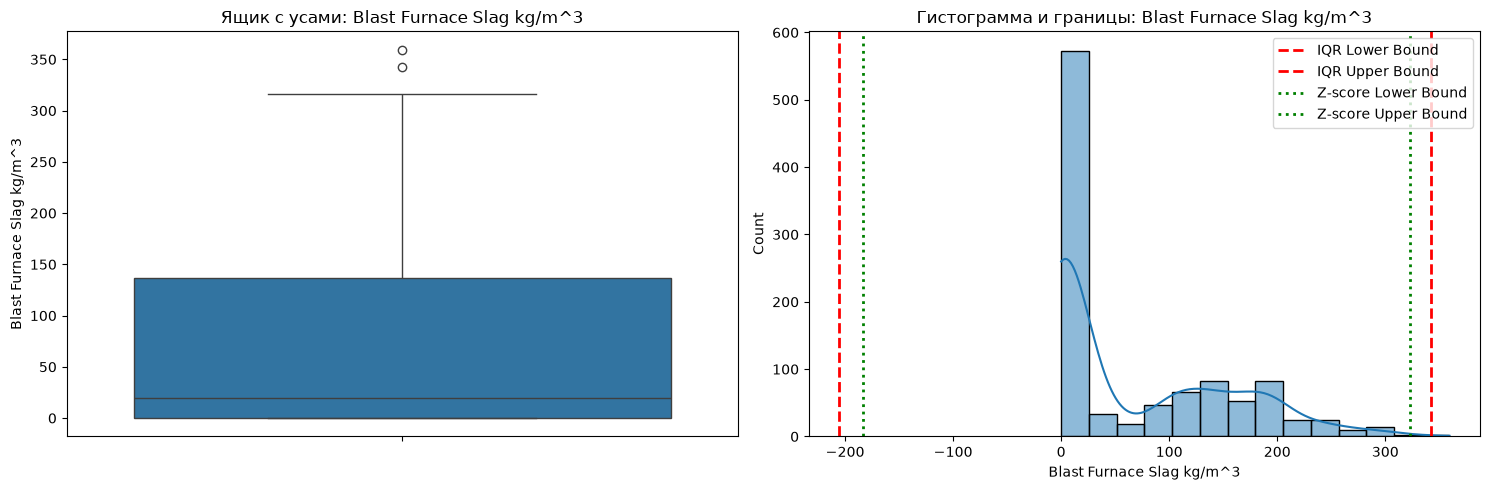

Выбросы по признаку 'Blast Furnace Slag kg/m^3' (пересечение IQR и Z-score): 2 строк(и)


,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
584,228.0,342.1,0.0,185.7,0.0,955.8,674.3,7.0,21.92
553,239.6,359.4,0.0,185.7,0.0,941.6,664.3,7.0,25.42


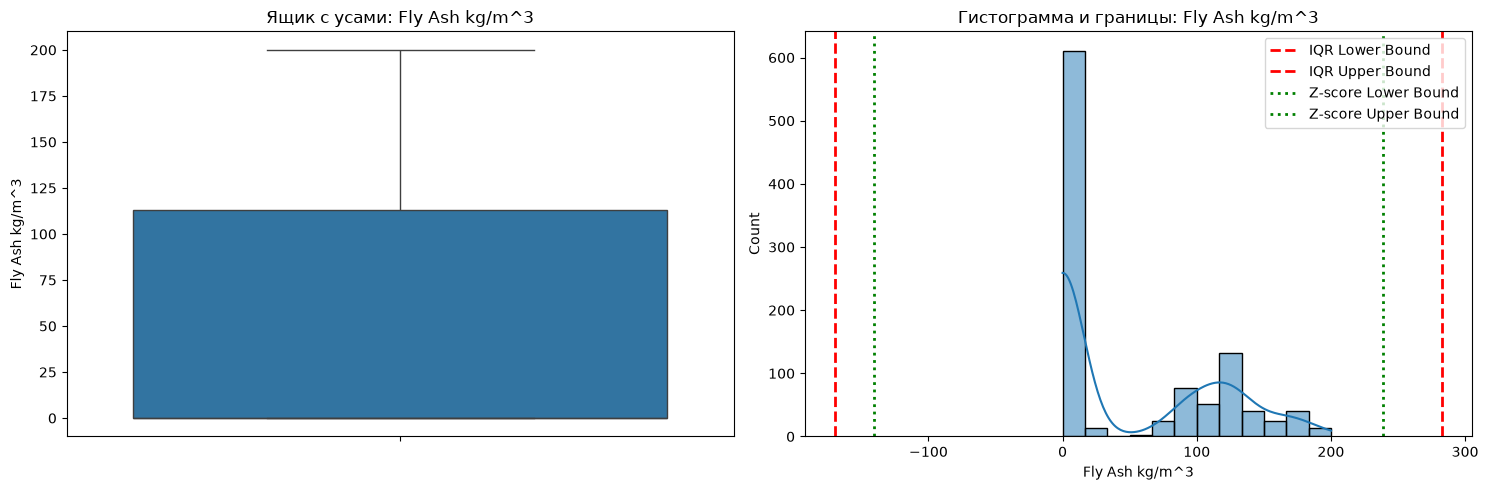

По признаку 'Fly Ash kg/m^3' общих выбросов (IQR + Z-score) не найдено



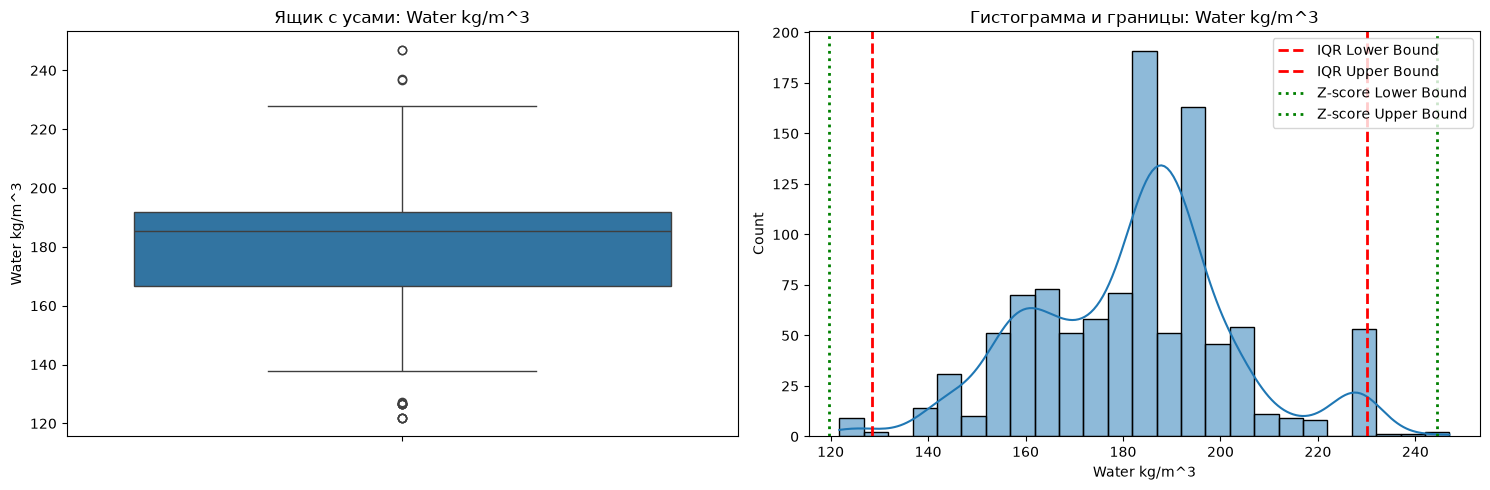

Выбросы по признаку 'Water kg/m^3' (пересечение IQR и Z-score): 2 строк(и)


,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
936,275.1,91.7,71.5,246.9,6.0,852.9,695.4,28.0,28.63
873,237.0,92.0,71.0,247.0,6.0,853.0,777.8,28.0,28.63


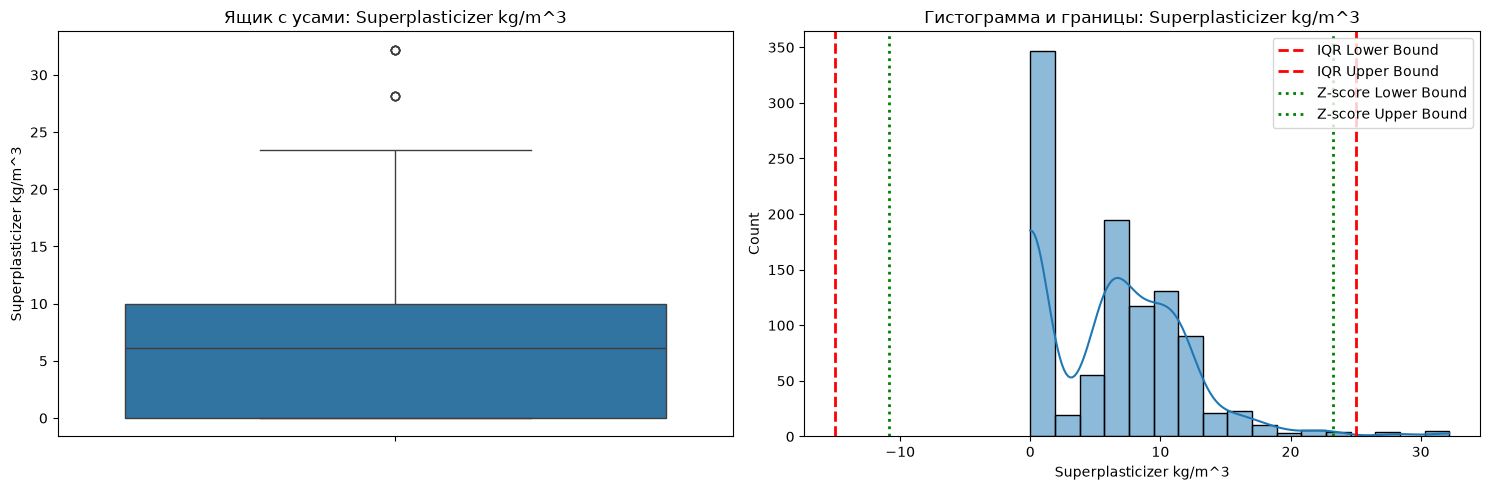

Выбросы по признаку 'Superplasticizer kg/m^3' (пересечение IQR и Z-score): 9 строк(и)


,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
99,275.1,117.2,0.0,137.8,32.2,852.1,840.5,7.0,54.9
102,275.1,0.0,0.0,141.8,28.2,852.1,893.7,7.0,46.9
168,469.0,117.2,0.0,137.8,32.2,852.1,840.5,91.0,70.7
171,531.3,0.0,0.0,141.8,28.2,852.1,893.7,91.0,59.2
76,469.0,117.2,0.0,137.8,32.2,852.1,840.5,3.0,40.2
79,531.3,0.0,0.0,141.8,28.2,852.1,893.7,3.0,41.3
145,469.0,117.2,0.0,137.8,32.2,852.1,840.5,56.0,69.3
148,531.3,0.0,0.0,141.8,28.2,852.1,893.7,56.0,58.8
122,469.0,20.0,0.0,137.8,32.2,852.1,840.5,28.0,66.9


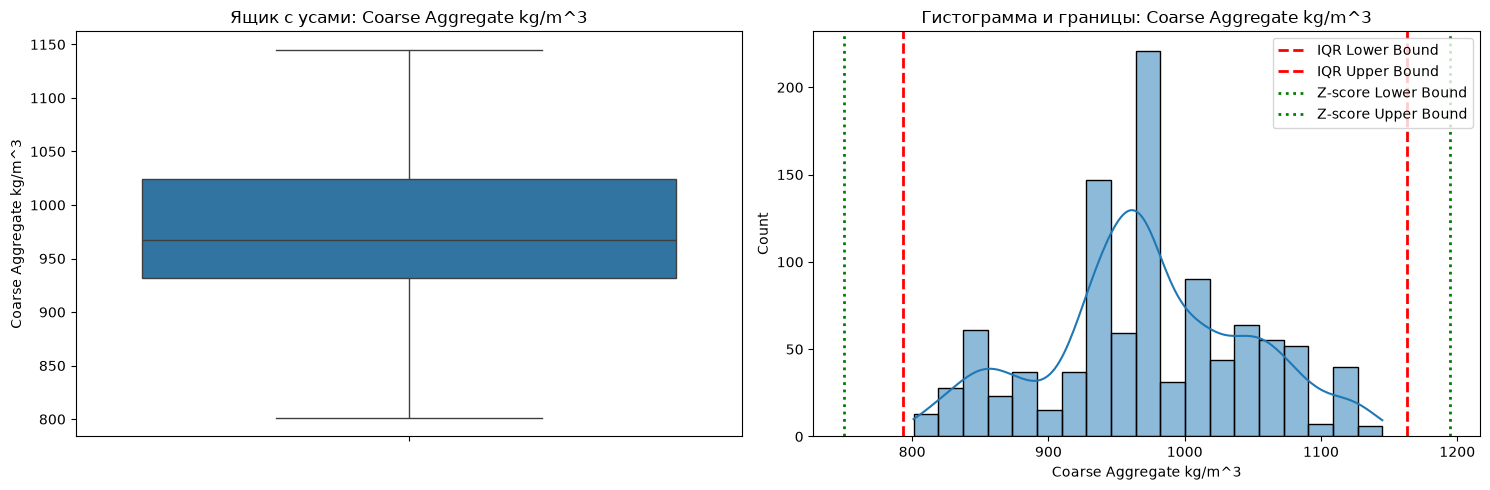

По признаку 'Coarse Aggregate kg/m^3' общих выбросов (IQR + Z-score) не найдено



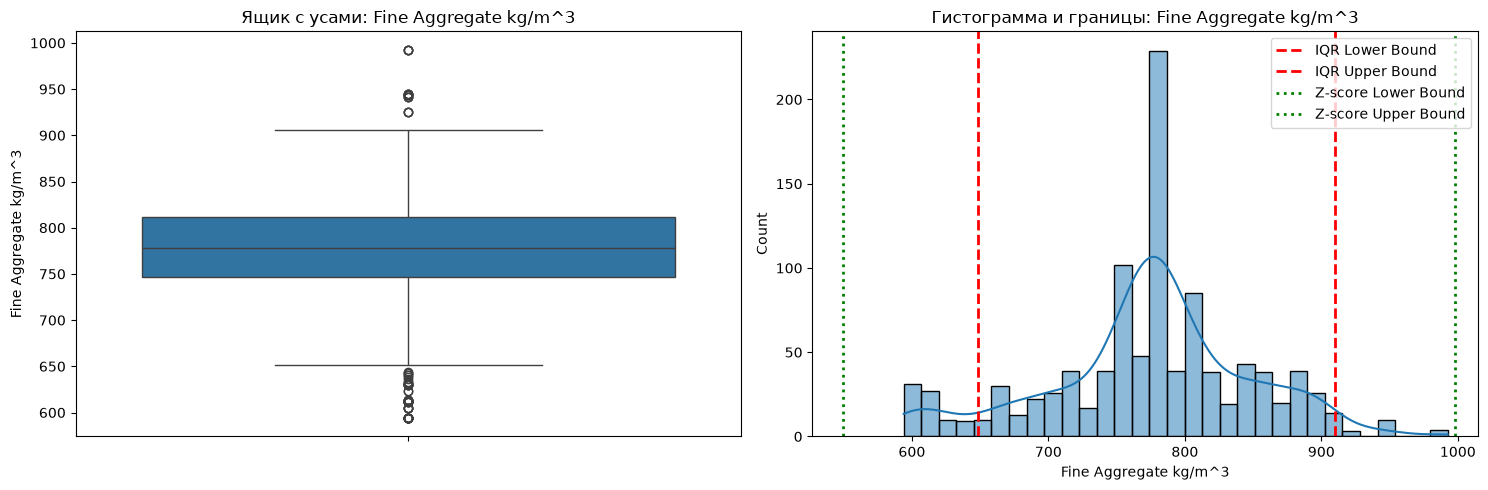

По признаку 'Fine Aggregate kg/m^3' общих выбросов (IQR + Z-score) не найдено



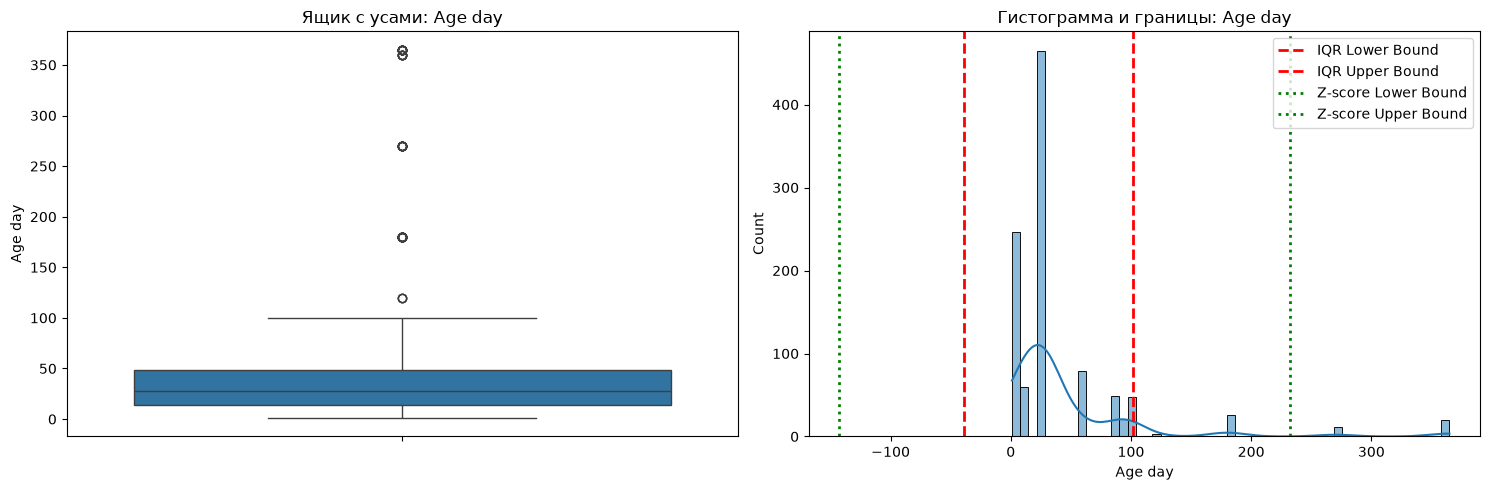

Выбросы по признаку 'Age day' (пересечение IQR и Z-score): 32 строк(и)


,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
769,331.0,0.0,0.0,192.00,0.0,978.00,825.0,360.0,41.24
2,332.5,142.5,0.0,228.00,0.0,932.00,594.0,270.0,40.27
3,332.5,142.5,0.0,228.00,0.0,932.00,594.0,365.0,41.05
4,198.6,132.4,0.0,192.00,0.0,978.40,825.5,360.0,44.30
6,380.0,95.0,0.0,228.00,0.0,932.00,594.0,365.0,43.70
12,427.5,47.5,0.0,228.00,0.0,932.00,594.0,270.0,43.01
17,342.0,20.0,0.0,228.00,0.0,932.00,670.0,365.0,56.14
792,349.0,0.0,0.0,185.35,0.0,1047.00,806.0,360.0,42.13
24,380.0,0.0,0.0,228.00,0.0,932.00,670.0,365.0,52.52
26,380.0,95.0,0.0,228.00,0.0,967.25,594.0,270.0,41.15




Итого уникальных строк на удаление (по всем признакам): 45


In [30]:
from scipy import stats

df_clean = X_clean.copy()
df_clean['Concrete compressive strength'] = y

global_common_outliers = set()
z_threshold = 3

for col in X_clean.columns:
    Q1 = X_clean[col].quantile(0.25)
    Q3 = X_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound_iqr = Q1 - 1.5 * IQR
    upper_bound_iqr = Q3 + 1.5 * IQR
    
    col_outliers_iqr = set(X_clean[(X_clean[col] < lower_bound_iqr) | (X_clean[col] > upper_bound_iqr)].index)
    
    col_zscore = np.abs(stats.zscore(X_clean[col]))
    col_outliers_zscore = set(X_clean[col_zscore > z_threshold].index)
    
    col_common_outliers = col_outliers_iqr.intersection(col_outliers_zscore)
    
    global_common_outliers.update(col_common_outliers)
    
    mean = X_clean[col].mean()
    std = X_clean[col].std()
    lower_bound_z = mean - z_threshold * std
    upper_bound_z = mean + z_threshold * std
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.boxplot(y=X_clean[col], ax=axes[0])
    axes[0].set_title(f'Ящик с усами: {col}')
    
    sns.histplot(X_clean[col], kde=True, ax=axes[1])
    
    axes[1].axvline(lower_bound_iqr, color='red', linestyle='dashed', linewidth=2, label='IQR Lower Bound')
    axes[1].axvline(upper_bound_iqr, color='red', linestyle='dashed', linewidth=2, label='IQR Upper Bound')
    axes[1].axvline(lower_bound_z, color='green', linestyle='dotted', linewidth=2, label='Z-score Lower Bound')
    axes[1].axvline(upper_bound_z, color='green', linestyle='dotted', linewidth=2, label='Z-score Upper Bound')
    
    axes[1].set_title(f'Гистограмма и границы: {col}')
    axes[1].legend(loc='upper right')
    
    plt.tight_layout()
    plt.show()
    
    if len(col_common_outliers) > 0:
        print(f"Выбросы по признаку '{col}' (пересечение IQR и Z-score): {len(col_common_outliers)} строк(и)")
        display(df_clean.loc[list(col_common_outliers)])
    else:
        print(f"По признаку '{col}' общих выбросов (IQR + Z-score) не найдено")
    print()

print(f"\nИтого уникальных строк на удаление (по всем признакам): {len(global_common_outliers)}")

### Интерпретация отклонений

При анализе распределения признаков были выявлены значения, которые статистические алгоритмы (IQR или Z-score) классифицируют как выбросы. Однако в контексте строительной физики эти данные являются не аппаратными ошибками, а граничными условиями эксперимента. Принято решение **оставить эти данные в обучающей выборке** по следующим причинам:

### Анализ значений Blast Furnace Slag (Доменный шлак)

* **Пропорции:** В этих рецептурах масса шлака превышает массу цемента (228.0 и 239.6 кг/м³). Это классический состав специализированных бетонов (например, на основе шлакопортландцемента), которые используются для массивных конструкций.
* **Плотность:** Суммарная масса всех компонентов в этих строках составляет около 2390 кг/м³, что идеально укладывается в норму плотности тяжелого бетона (2300–2500 кг/м³).

### Анализ значений Water (Количество воды)

* **Пропорции:** Водовяжущее отношение (вода ко всей сумме вяжущих компонентов: цемент + шлак + зола) составляет 0.56–0.61. Это абсолютная технологическая норма для строительных смесей.
* **Плотность:** Суммарная масса всех компонентов в строках (около 2240–2284 кг/м³) соответствует стандартам плотности.

### Анализ значений Superplasticizer (Суперпластификатор, добавка)

* **Технология:** Аномально высокие дозы суперпластификатора (28.2 и 32.2 кг/м³) применяются целенаправленно для экстремального снижения количества воды при сохранении текучести. В этих строках мы видим очень низкое содержание воды — всего 137.8–141.8 кг/м³.
* **Прочность:** За счет сильного снижения объема воды (низкое водоцементное отношение) прочность этих образцов достигает высоких значений — от 58 до 70 МПа на поздних сроках твердения (56–91 день).
* **Плотность:** Суммарная масса компонентов в этих строках составляет около 2450 кг/м³, что идеально соответствует плотности стандартного тяжелого бетона.

### Анализ значений Age day (Время выдержки)

* Максимальное значение в 365 дней статистически выглядит как выброс на фоне медианы в 28 дней. Но процесс гидратации цемента не останавливается через месяц, он длится годами. Сохранение этих данных критически важно для проверки гипотезы заказчика о влиянии времени на долгосрочную прочность. Проблема экстремального разброса времени решается не удалением строк, а применением логарифмического закона роста прочности (как и описывалось при первоначальном анализе признаков)

## 3.2. Детекция аномалий в данных

Многомерные выбросы могут сместить веса признаков и исказить результаты обучения. Однако, прежде чем принимать решение об их удалении, мы должны **найти и детально проанализировать** эти объекты, поскольку физически они могут представлять собой корректные, но экстремальные рецептуры.

Для надежного поиска применяется ансамблевый подход:

* **Масштабирование:** Приведение данных к единому масштабу через `StandardScaler`.
* **Детекция:** Поиск аномалий тремя независимыми алгоритмами - `IsolationForest`, `OneClassSVM` и `DBSCAN`.
* **Ансамблирование:** Строгое пересечение результатов. Объект лишь *помечается* как потенциальный выброс для дальнейшего исследования в том случае, если хотя бы 2 алгоритма классифицируют его как аномалию.

In [81]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import umap

In [82]:
# Визуализация аномальных объектов
def draw_anomaly(X_2d: np.ndarray, anomaly_mask: np.ndarray) -> None:
    plt.scatter(X_2d[:, 0], X_2d[:, 1])
    plt.scatter(X_2d[anomaly_mask, 0], X_2d[anomaly_mask, 1], c="red", marker='x')


In [83]:
# Визуализация долей аномальных и неаномальных объектов в данных
def draw_anomaly_pie(anomaly_mask: np.ndarray) -> None:
    _, counts = np.unique(anomaly_mask, return_counts=True)
    plt.pie(counts, labels=counts, autopct='%1.0f%%')
    plt.legend(['Нормальные объекты', 'Аномалии'], loc='lower right')

In [84]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [85]:
reducer = umap.UMAP(random_state=42)
X_2d = reducer.fit_transform(X_train_scaled)

### Isolation Forest

In [86]:
iso = IsolationForest(contamination=0.05, random_state=42)
iso_preds = iso.fit_predict(X_train_scaled)

is_anomaly_iso = (iso_preds == -1)
print(f"Найдено аномалий (Isolation Forest): {is_anomaly_iso.sum()}")

Найдено аномалий (Isolation Forest): 42


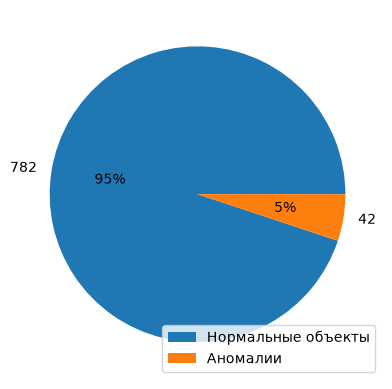

In [87]:
draw_anomaly_pie(is_anomaly_iso)

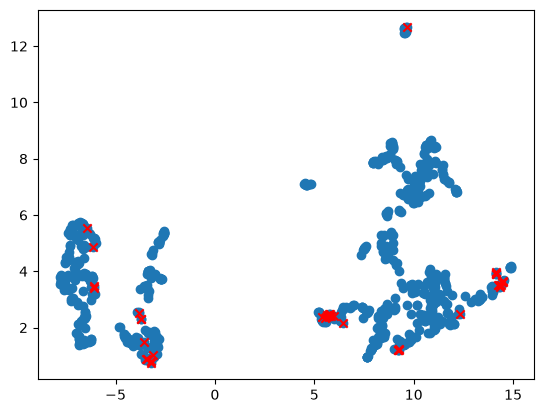

In [88]:
draw_anomaly(X_2d, is_anomaly_iso)

Четких плотных кластеров не найдено, однако объекты в нескольких местах скапливаются

### SVM

In [89]:
svm = OneClassSVM(nu=0.05)
svm_preds = svm.fit_predict(X_train_scaled)

is_anomaly_svm = (svm_preds == -1)
print(f"Найдено аномалий (One-Class SVM): {is_anomaly_svm.sum()}")

Найдено аномалий (One-Class SVM): 44


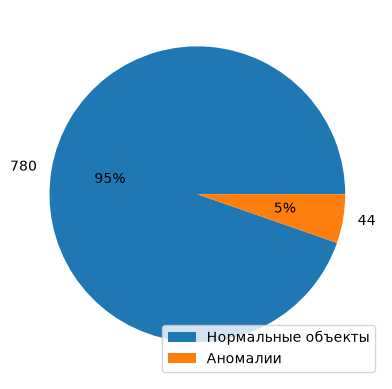

In [90]:
draw_anomaly_pie(is_anomaly_svm)

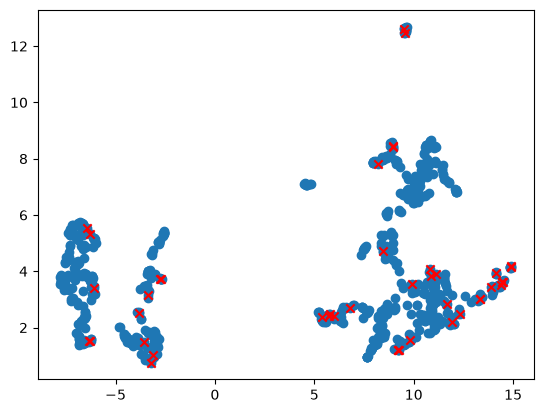

In [91]:
draw_anomaly(X_2d, is_anomaly_svm)

Четких плотных кластеров не найдено, но в отличие от IF у SVM аномальные объекты более разбросаны

### DBSCAN

In [92]:
dbscan = DBSCAN(eps=2.5, min_samples=8)
dbscan_preds = dbscan.fit_predict(X_train_scaled)

is_anomaly_dbscan = (dbscan_preds == -1)
print(f"Найдено аномалий (DBSCAN): {is_anomaly_dbscan.sum()}")

Найдено аномалий (DBSCAN): 3


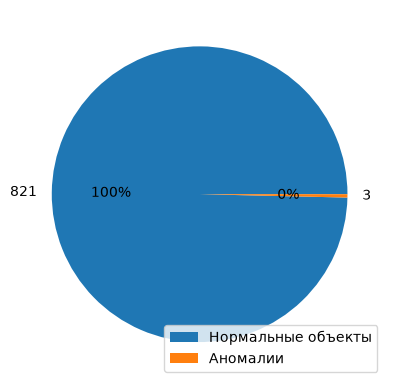

In [93]:
draw_anomaly_pie(is_anomaly_dbscan)

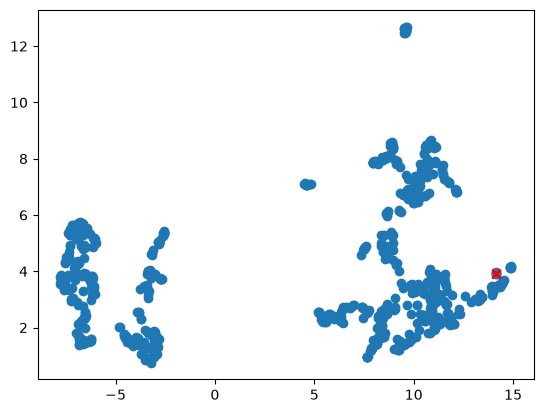

In [94]:
draw_anomaly(X_2d, is_anomaly_dbscan)

Все три аномалии скопились в одном месте

### Пересечение

In [ ]:
anomalies = (is_anomaly_iso.astype(int) + is_anomaly_svm.astype(int) + is_anomaly_dbscan.astype(int)) >= 2
print(f"Найдено аномалий (Пересечение >= 2 алгоритмов): {anomalies.sum()}")

Найдено аномалий (Пересечение >= 2 алгоритмов): 21


In [96]:
anomalies_X = X_train[anomalies]
anomalies_y = y_train[anomalies]

anomalies_full_df = pd.concat([anomalies_X, anomalies_y], axis=1)

display(anomalies_full_df)

,Cement kg/m^3,Blast Furnace Slag kg/m^3,Fly Ash kg/m^3,Water kg/m^3,Superplasticizer kg/m^3,Coarse Aggregate kg/m^3,Fine Aggregate kg/m^3,Age day,Concrete compressive strength
798,500.0,0.0,0.0,200.00,0.0,1125.00,613.0,270.0,55.16
830,162.0,190.0,148.0,179.00,19.0,838.00,741.0,28.0,33.76
974,148.1,0.0,182.1,181.40,15.0,838.90,884.3,28.0,15.53
228,168.0,42.1,163.8,121.80,5.7,1058.70,780.1,100.0,39.23
79,531.3,0.0,0.0,141.80,28.2,852.10,893.7,3.0,41.30
820,525.0,0.0,0.0,189.00,0.0,1125.00,613.0,270.0,67.11
41,427.5,20.0,0.0,228.00,0.0,967.25,594.0,365.0,43.70
108,379.5,151.2,0.0,153.90,15.9,1134.30,605.0,7.0,47.10
56,475.0,0.0,0.0,228.00,0.0,932.00,594.0,365.0,41.93
932,154.0,174.0,185.0,228.00,6.1,845.00,777.8,28.0,24.34


Отклонения обусловлены спецификой рецептур и условиями испытаний, которые редко встречаются в базовой массе данных, но абсолютно оправданы с точки зрения технологии бетонов:

1. **Долгосрочные испытания (Age day):** В отфильтрованном списке присутствуют образцы, тестировавшиеся на поздних сроках твердения — 100, 270 и 365 дней. Для понимания процесса набора прочности и проверки гипотез о долговечности эти данные критически важны.
2. **Сверхпрочные бетоны (Низкое содержание воды + Суперпластификаторы):** В выборке присутствуют смеси, где за счет высокой дозировки суперпластификатора (вплоть до 32.2 кг/м³) объем воды экстремально снижен (до 121.8 - 141.8 кг/м³). Такая технология применяется для получения высокомарочных бетонов, что подтверждается их высокой фактической прочностью (до 74 МПа). 
3. **Альтернативные вяжущие (Шлак, Зола-унос):** Наблюдаются экологичные и специальные рецептуры, где шлак или зола используются в больших объемах (замещая часть цемента) для снижения тепловыделения при заливке массивных конструкций. Общая плотность таких смесей остается в пределах стандартов тяжелого бетона, что доказывает физическую корректность пропорций.

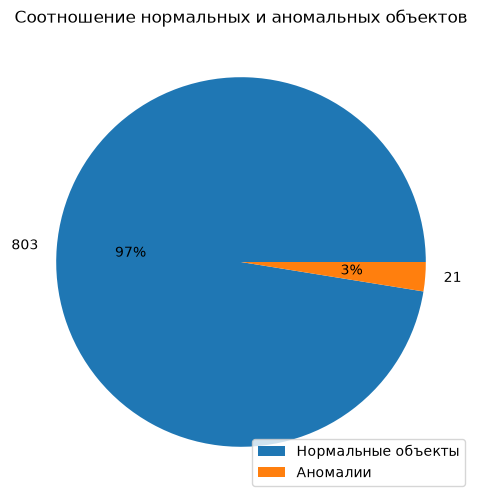

In [97]:
plt.figure(figsize=(6, 6))
draw_anomaly_pie(anomalies)
plt.title('Соотношение нормальных и аномальных объектов')
plt.show()

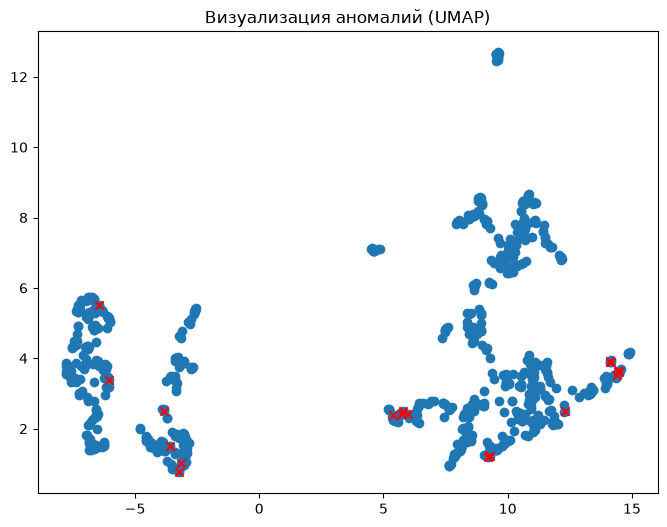

In [98]:
plt.figure(figsize=(8, 6))
draw_anomaly(X_2d, anomalies)
plt.title('Визуализация аномалий (UMAP)')
plt.show()

### Итоговое решение: сохранение данных

Несмотря на то, что ансамбль алгоритмов выявил ряд многомерных выбросов, детальный анализ показал, что эти наблюдения **не являются ошибками**. Это редкие, но технологически корректные рецептуры.

**Решение: мы не удаляем найденные аномалии из датасета** 

Исключение этих строк лишит модель ценной информации о поведении специфических смесей. Поскольку данные остаются в выборке в первозданном виде, для дальнейшего обучения мы сделаем упор на алгоритмы, обладающие естественной устойчивостью к выбросам (например, ансамбли на основе деревьев решений).